# RillWatch: Stream Quality & Prediction Observability

Measured synthetic scenarios, real TCP verification, and explicit operating boundaries. The notebook reads released evidence; it does not launch a long-running server or train a model.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from rillwatch.framing import Framer
from rillwatch.validation import parse

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = ROOT.parent


def read(path):
    return json.loads((ROOT / path).read_text())


summary = read("reports/summary.json")
summary

{'events_across_scenarios': 86400,
 'stable_alerts': 0,
 'shifted_runs_with_all_targets': 3,
 'capacity_evictions': 0,
 'runtime': {'python': '3.12.14', 'system': 'Darwin', 'architecture': 'arm64'},
 'csv_sample_limit': 25}

## Strict framing and validation

TCP packets do not define record boundaries. UTF-8 bytes stay buffered until a newline appears; oversized frames are quarantined and resynchronized. Multiple validation errors are retained.

In [2]:
framer = Framer()
assert framer.feed(b'{"x":') == []
frames = framer.feed(b"1}\n")
assert frames[0].raw == b'{"x":1}'
record, problems = parse((ROOT / "data/examples/invalid.json").read_bytes())
assert len(problems) >= 3
problems

['reading_id_invalid', 'confidence_score_invalid', 'response_time_ms_invalid']

## Measured event accounting

Each scenario advances a deterministic receipt clock through 360 simulated seconds at 40 events/second. These replay runs are accelerated, not wall-clock TCP throughput tests.

,scenario,seed,events,clean,bad,alert_emissions,local_replay_events_per_second
0,stable,42,14400,14071,329,0,22287.621878
1,stable,7,14400,14031,369,0,21862.644143
2,stable,19,14400,14024,376,0,22350.937026
3,shifted,42,14400,14071,329,9,21938.981975
4,shifted,7,14400,14031,369,9,22076.982896
5,shifted,19,14400,14024,376,9,21826.727875


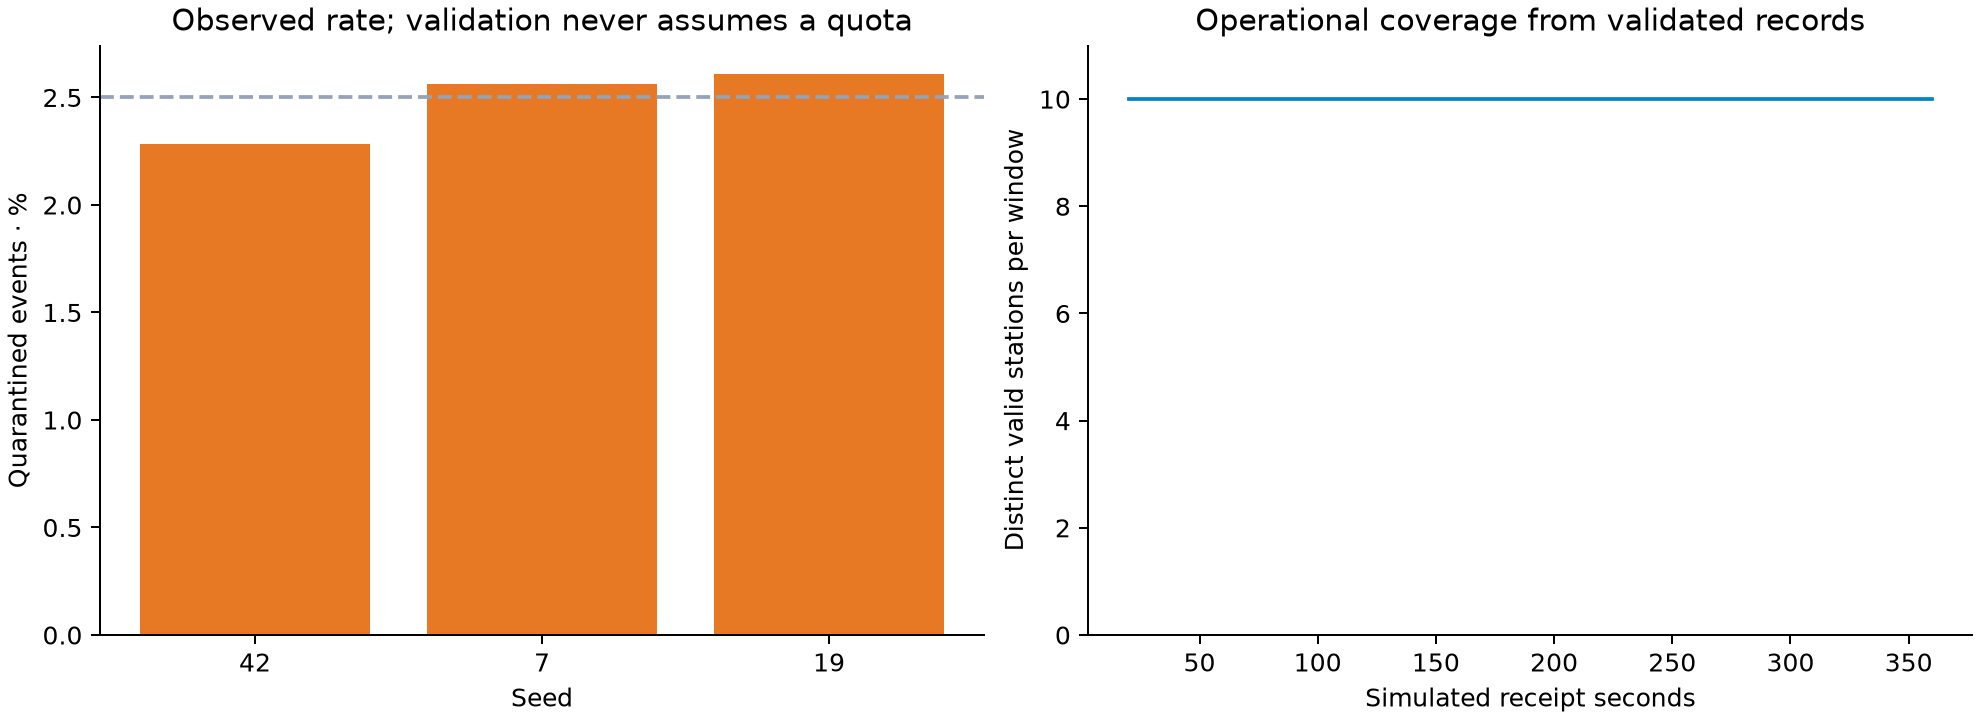

In [3]:
results = read("reports/benchmark.json")
table = pd.DataFrame(
    [
        {
            "scenario": r["scenario"],
            "seed": r["seed"],
            "events": r["events"],
            "clean": r["counts"]["clean"],
            "bad": r["counts"]["bad"],
            "alert_emissions": len(r["alerts"]),
            "local_replay_events_per_second": r["local_events_per_second"],
        }
        for r in results
    ]
)
assert table["events"].sum() == 86400
assert ((table["clean"] + table["bad"]) == table["events"]).all()
display(table)
display(Image(filename=str(ROOT / "reports/figures/quality_coverage.png")))

## Valid telemetry can still shift

Schema validation and model-behavior monitoring answer different questions. Compare stable and shifted runs on confidence and latency; no actual-outcome labels are available to establish a change in prediction accuracy.

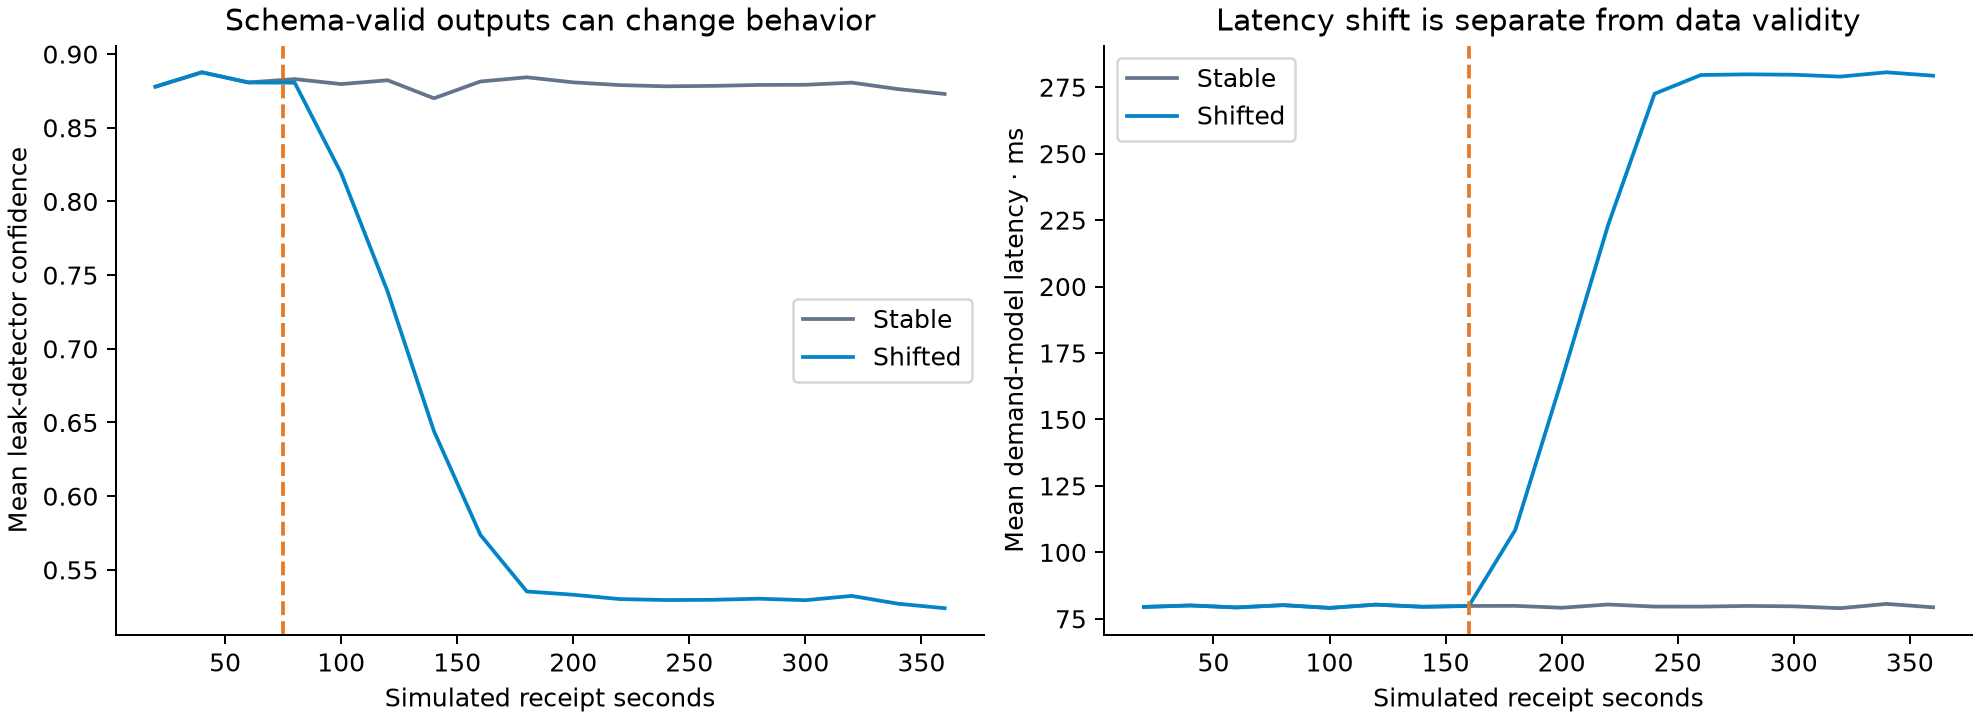

,received,window_total,window_bad,active_stations
0,20,800,13,10
1,40,800,11,10
2,60,800,18,10
3,80,800,20,10
4,100,800,17,10
5,120,800,25,10
6,140,800,14,10
7,160,800,15,10
8,180,800,23,10
9,200,800,17,10


In [4]:
display(Image(filename=str(ROOT / "reports/figures/behavior_shifts.png")))
windows = pd.DataFrame(read("reports/shifted_windows.json"))
assert windows["window_total"].sum() == 14400
display(windows[["received", "window_total", "window_bad", "active_stations"]])

## Detection delay and repeated alerts

Effect-size gates, minimum sample counts, two consecutive checks, and cooldown are operational heuristics. Overlapping windows are correlated. Alert counts include cooldown repeats, so they must not be interpreted as independent true positives.

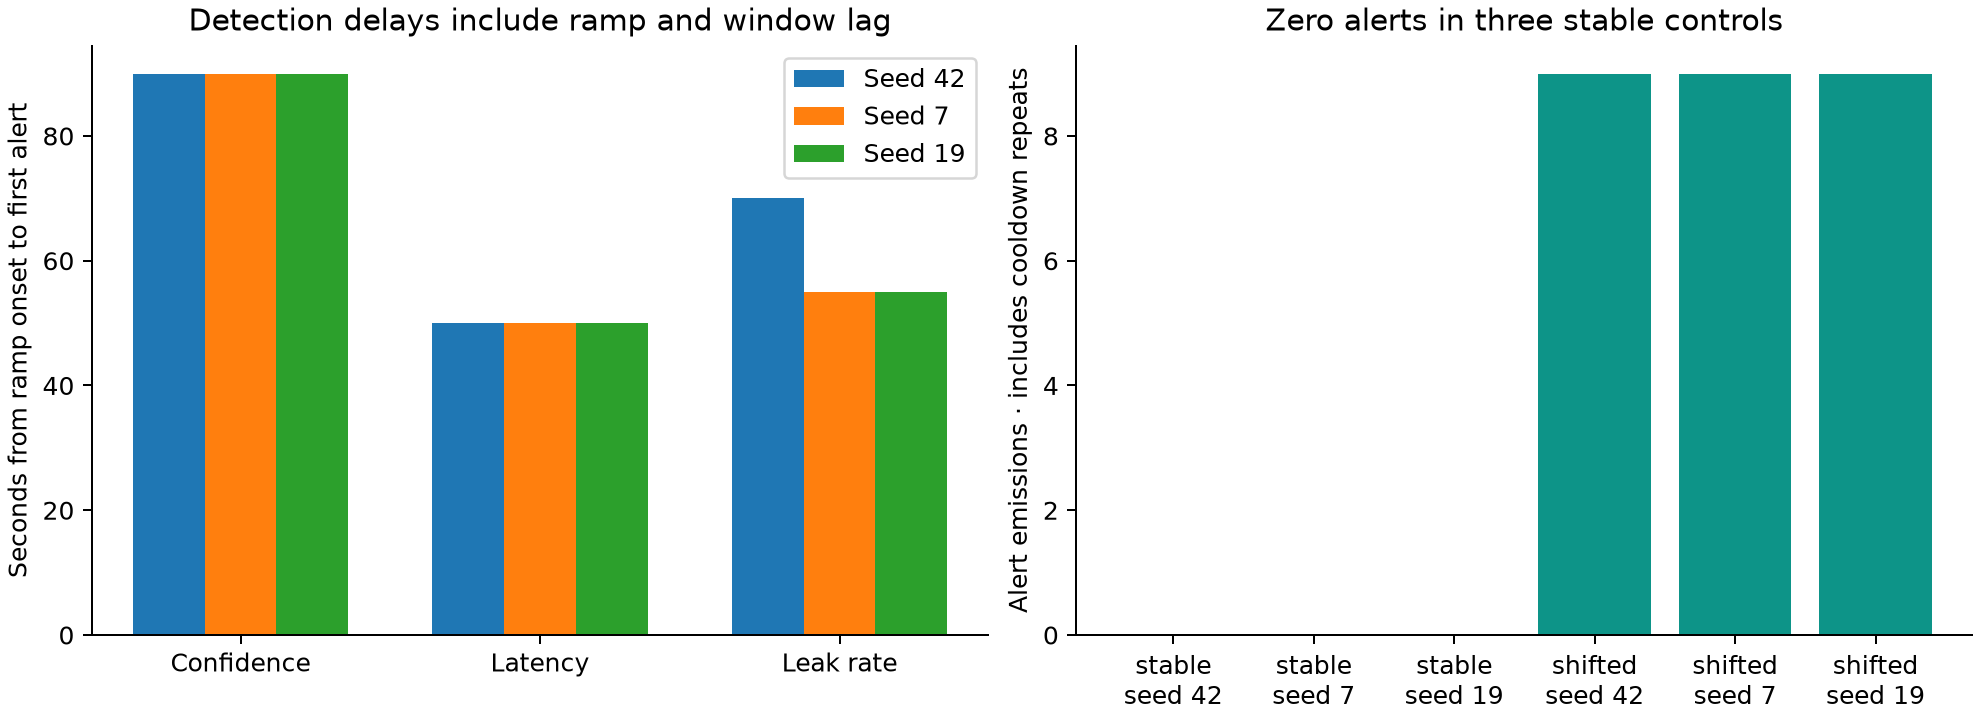

,run_id,received,model_name,metric,baseline_mean,recent_mean,score,score_kind,baseline_n,recent_n,consecutive_checks
0,shifted-42,165,leak_detector,confidence_score,0.882088,0.600958,-4.296353,baseline_standardized_effect,791,587,2
1,shifted-42,210,demand_forecaster,response_time_ms,79.588899,158.041174,8.214682,baseline_standardized_effect,782,585,2
2,shifted-42,225,leak_detector,confidence_score,0.882088,0.532214,-5.346939,baseline_standardized_effect,791,583,6
3,shifted-42,270,demand_forecaster,response_time_ms,79.588899,278.787960,20.857992,baseline_standardized_effect,782,593,6
4,shifted-42,285,leak_detector,confidence_score,0.882088,0.529019,-5.395762,baseline_standardized_effect,791,584,10
5,shifted-42,300,leak_detector,leak_rate,0.085967,0.433219,15.045894,pooled_proportion_score,791,584,2
6,shifted-42,330,demand_forecaster,response_time_ms,79.588899,279.510777,20.933678,baseline_standardized_effect,782,583,10
7,shifted-42,345,leak_detector,confidence_score,0.882088,0.528440,-5.404615,baseline_standardized_effect,791,579,14
8,shifted-42,360,leak_detector,leak_rate,0.085967,0.611015,20.808912,pooled_proportion_score,791,581,6


In [5]:
display(Image(filename=str(ROOT / "reports/figures/detection_evidence.png")))
alerts = pd.DataFrame(
    next(r for r in results if r["scenario"] == "shifted" and r["seed"] == 42)["alerts"]
)
display(alerts)
assert all(not r["alerts"] for r in results if r["scenario"] == "stable")

## Independent live TCP evidence

The separate loopback run takes at least 360 real seconds. Actual throughput can be below the simulator's nominal 40 events/second because scheduling and synchronous persistence affect pacing.

In [6]:
live = read("reports/live_run.json")
assert live["duration_seconds"] >= 360
live

{'connections': 1,
 'disconnects': 1,
 'idle_timeouts': 0,
 'duration_seconds': 360.12790425000003,
 'counts': {'bad': 306, 'clean': 13416},
 'capacity_evictions': 0,
 'alert_count': 9,
 'report_count': 19}

## Delivery and scaling decisions

SQLite commits each frame and its classification together. Same local event identity and bytes replay idempotently, while conflicting identities fail. This is not an end-to-end losslessness guarantee: raw TCP has no replay/acknowledgement contract, and in-memory monitoring state rewarms after restart. The local replay measurement is not a 50,000-events/second deployment claim. Broker-backed delivery, consistent state checkpoints, retention, and representative seasonal data are further engineering work.